In [1]:
import sys
sys.path.append("../")

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import expm
from qiskit.quantum_info import Statevector, SparsePauliOp
from cqite.engine.unitary_approximation import UnitaryApproximation
from cqite.engine.propagation import QITEPropagation
from cqite.engine.cqite_run import cqite_cycle
from cqite.engine.prepare_state import constraint_rotation, prepare_state, density_from_rotations, support_only
from cqite.simulation.backend import SimulatorBackend

from cqite.ansatz.commutator_basis import CommutatorBasis

In [52]:
depth=1
dt=1e-2
nqubits = 6
degree = 2
nsteps = 1000

In [54]:
target=[0.7, 0.75, 0.8, 0.85, 0.9, 0.95]

energies=[]
fidelities=[]
errors=[]
magnetizations=[]

In [56]:
Jzz = 0.2
Jxx = 0.2
n = nqubits

edges = [(1,2), (1,3), (2,3), (2,4), (3,4), (0,2), (0,4), (0,5), (4,5)]

paulis = []
coeffs = []

for u, v in edges:
    s = ["I"] * n
    s[u] = "Z"
    s[v] = "Z"
    paulis.append("".join(s))
    coeffs.append(Jzz)

    s = ["I"] * n
    s[u] = "X"
    s[v] = "X"
    paulis.append("".join(s))
    coeffs.append(Jxx)

H = SparsePauliOp(paulis, coeffs=coeffs)

In [58]:
from qiskit.quantum_info import SparsePauliOp

n = nqubits

C = []

for i in range(n):
    s = ["I"] * n
    s[i] = "Y"
    C.append(
        SparsePauliOp(["".join(s)], coeffs=[1.0])
    )

In [60]:
G = H + sum(C[1:], start=C[0])

In [62]:
rotations = []

for j in range(nqubits):
    rotations.append(constraint_rotation(C[j], target[j]))

In [64]:
rho = density_from_rotations(nqubits, rotations, degree=degree)
#seeds = support_only(rho)

In [66]:
seeds = support_only(CommutatorBasis.commutator(H, support_only(rho)))

if seeds is None:
    raise ValueError(
        "The imaginary-time seed A(0) = -i[H, Phi_d(0)] vanishes."
    )

In [68]:
basis = CommutatorBasis.from_seed(hamiltonian=H, seeds=seeds, depth=depth)

In [69]:
len(basis.paulis)

296

In [72]:
circuit = prepare_state(nqubits, rotations).decompose()

In [74]:
backend = SimulatorBackend()

In [76]:
APX = UnitaryApproximation(basis, trot=2)

prop = QITEPropagation(H, C, backend, APX)

prop.constraints.extend(C)

In [77]:
from qiskit.quantum_info import Statevector

psi = Statevector.from_instruction(circuit)

In [80]:
results = cqite_cycle(prop, None, H, C, dt, nsteps, state=psi)

QITE:   0%|          | 0/1000 [00:00<?, ?it/s]

In [82]:
energies = results["energies"]
magnetizations = results["magnetizations"] #[np.sum(m) for m in results["magnetizations"]]
final_circuit = results["circuit"]
final_state = results["state"]

In [84]:
print(np.round(energies[-1],3))

-0.296


In [86]:
print(np.round(magnetizations[-1],3))

[0.699 0.749 0.797 0.849 0.898 0.949]


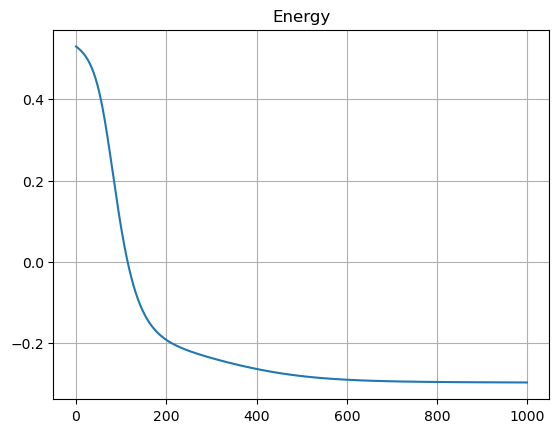

In [88]:
plt.plot(energies); plt.title('Energy'); plt.grid(); plt.show()

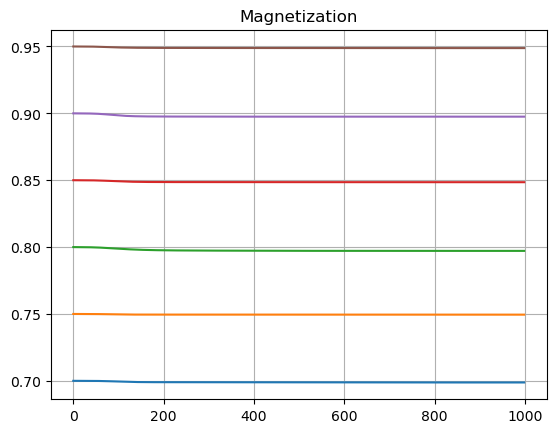

In [90]:
plt.plot(magnetizations); plt.title("Magnetization"); plt.grid(); plt.show()

In [92]:
evals = np.linalg.eigvalsh(
    H.to_matrix()
)

print("Exact spectrum")

print(np.round(evals,2))

Exact spectrum
[-1.48 -1.25 -1.25 -1.05 -1.   -1.   -0.96 -0.95 -0.88 -0.88 -0.86 -0.84
 -0.84 -0.72 -0.72 -0.72 -0.69 -0.64 -0.64 -0.59 -0.59 -0.4  -0.39 -0.39
 -0.35 -0.31 -0.31 -0.24 -0.24 -0.24 -0.24 -0.18 -0.18 -0.18 -0.12 -0.
  0.    0.04  0.04  0.2   0.33  0.35  0.35  0.4   0.5   0.5   0.5   0.57
  0.57  0.57  0.57  0.71  0.74  0.74  0.87  1.03  1.21  1.21  1.27  1.27
  1.48  2.01  2.01  2.24]


In [94]:
def compute_betas_dense(psi, Hm, constraints):

    m = len(constraints)

    gamma = np.zeros(m)
    Gmat = np.zeros((m,m))

    Hpsi = Hm @ psi

    for i, Bi in enumerate(constraints):

        Bipsi = Bi @ psi

        gamma[i] = -np.real(
            np.vdot(Hpsi, Bipsi)
        )

        for j, Bj in enumerate(constraints):

            Gmat[i,j] = np.real(
                np.vdot(
                    Bipsi,
                    Bj @ psi
                )
            )

    return np.linalg.pinv(Gmat) @ gamma

In [96]:
Hm = H.to_matrix()

In [98]:
Cm = [Cj.to_matrix() for Cj in C]

I = np.eye(Hm.shape[0])

constraints_mat = [I]
constraints_mat.extend(Cm)

In [100]:
from scipy.sparse.linalg import expm_multiply

def cite_step(
    psi,
    Hm,
    constraints_mat,
    dt,
    nsub=100
):

    h = dt / nsub

    for _ in range(nsub):

        beta = compute_betas_dense(
            psi,
            Hm,
            constraints_mat
        )

        G = Hm.copy()

        for b, B in zip(beta, constraints_mat):
            G += b * B

        psi = expm_multiply(-h * G, psi)
        psi /= np.linalg.norm(psi)

    return psi

In [102]:
import numpy as np
from tqdm.notebook import tqdm

energies_exact = []
constraints_history = [[] for _ in Cm]

append_energy = energies_exact.append
append_constraints = [hist.append for hist in constraints_history]

psi_exact = psi.data

for step in tqdm(range(nsteps), desc="CITE"):

    psi_exact = cite_step(
        psi_exact,
        Hm,
        constraints_mat,
        dt=dt
    )

    append_energy(
        np.real(
            np.vdot(
                psi_exact,
                Hm @ psi_exact
            )
        )
    )

    for append, B in zip(append_constraints, constraints_mat):

        append(
            np.real(
                np.vdot(
                    psi_exact,
                    B @ psi_exact
                )
            )
        )

CITE:   0%|          | 0/1000 [00:00<?, ?it/s]

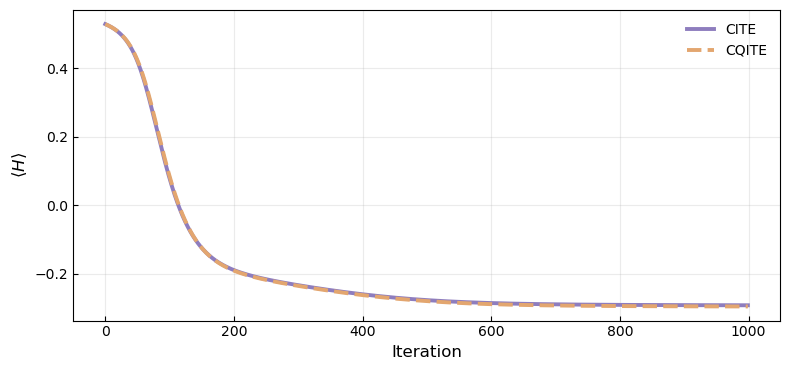

In [114]:
import numpy as np
import matplotlib.pyplot as plt

energies = np.asarray(energies)
energies_exact = np.asarray(energies_exact)

iters = np.arange(len(energies))

fig, ax = plt.subplots(
    figsize=(8, 3.8),
    dpi=100
)

# Palette viola + arancione tenue
cite_color = "#8E7DBE"      # muted violet
cqite_color = "#E3A66F"     # soft orange

ax.plot(
    iters,
    energies_exact,
    lw=2.8,
    color=cite_color,
    label="CITE"
)

ax.plot(
    iters,
    energies,
    lw=2.8,
    ls="--",
    color=cqite_color,
    label="CQITE"
)

ax.set_xlabel("Iteration", fontsize=12)
ax.set_ylabel(r"$\langle H\rangle$", fontsize=12)

ax.grid(True, alpha=0.25)
ax.legend(frameon=False)

ax.tick_params(direction="in")

plt.tight_layout()
fig.savefig("zzxxy_exp.pdf", bbox_inches="tight", transparent=True)

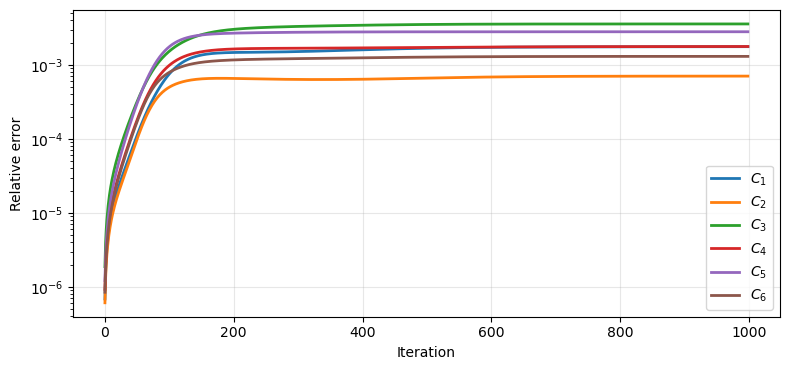

In [108]:
mag = np.asarray(magnetizations)

fig, ax = plt.subplots(
    figsize=(8, 3.8)
)

eps = 5e-3

for k in range(mag.shape[1]):

    rel_error = np.abs((mag[:, k] - target[k]) / target[k])

    ax.plot(
        rel_error * (1 + k * eps),
        lw=2,
        label=rf"$C_{k+1}$"
    )

ax.set_yscale("log")

ax.set_xlabel("Iteration")
ax.set_ylabel(r"Relative error")
ax.grid(alpha=.3)

ax.legend()

plt.tight_layout()

fig.savefig("zzxxy_con.pdf", bbox_inches="tight", transparent=True)